### 

- generate 1000 points
- keep them fixed
- for each class
    -  select one (maybe multiple, for robustness) examples
    - create and write a df with this example copied to the 1000 points
    - predict
    - visualize the preds (plus mark where the original point is) 
    
    
- i should do it for multiple examples of each class, and also for multiple seeds just to know how robust it is


In [1]:
import sys
import os
sys.path.append('../')


import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
import pickle
import pprint

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
from shapely.geometry import box
from shapely.ops import nearest_points

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier
from utils import get_tiles_as_gdf

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

np.set_printoptions(suppress=True)

In [2]:

palm = gpd.read_file('/home/jan/Documents/EPFL/project_2/data/tmp/palm_oil_80103253.gpkg')
urban = gpd.read_file('/home/jan/Documents/EPFL/project_2/data/tmp/urban_17_11_var.gpkg')
palm['prediction'] = palm.prediction.map(inverse_label_mapping)
urban['prediction'] = urban.preds_jp9ukkg4.map(inverse_label_mapping)

In [3]:
gdf = palm

In [4]:
gdf.crs  = 4326

In [7]:
gdf

,driver,sampleid,dataset,country,block_id,split,dst_size,prediction,probability,geometry
0,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.958363,POINT (18.22570 4.97070)
1,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.906301,POINT (145.26351 -17.83159)
2,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.974375,POINT (140.28276 -2.90154)
3,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.855646,POINT (133.55574 -13.42457)
4,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,forest plantation,0.162433,POINT (-39.90054 -9.35212)
...,...,...,...,...,...,...,...,...,...,...
995,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.955374,POINT (-10.02559 11.13743)
996,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.961816,POINT (29.68797 -13.23715)
997,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.965815,POINT (29.35990 -5.99571)
998,palm oil,80103253,mapbiomas_indonesia.csv,Indonesia,203.0,val,None,palm oil,0.924288,POINT (44.72622 -21.25744)


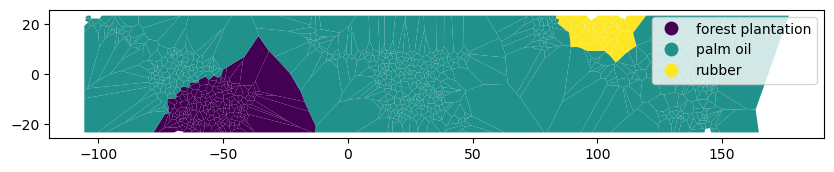

In [5]:
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
from scipy.spatial import Voronoi
import matplotlib.pyplot as plt
import numpy as np

def voronoi_polygons(points, categories, bounding_box):
    vor = Voronoi(points)
    regions, vertices = vor.regions, vor.vertices

    polygons = []
    for point_index, region_index in enumerate(vor.point_region):
        region = regions[region_index]
        if -1 in region or len(region) == 0:
            continue  # Skip open regions
        polygon = Polygon([vertices[i] for i in region])
        polygons.append((polygon, categories[point_index]))
    
    # Clip polygons to the bounding box
    bbox_polygon = Polygon.from_bounds(*bounding_box)
    clipped_polygons = []
    for poly, category in polygons:
        clipped = poly.intersection(bbox_polygon)
        if not clipped.is_empty:
            if isinstance(clipped, Polygon):
                clipped_polygons.append((clipped, category))
            elif isinstance(clipped, MultiPolygon):
                for sub_poly in clipped:
                    clipped_polygons.append((sub_poly, category))
    
    return clipped_polygons

# Example usage
# Assuming `gdf` is your GeoDataFrame with a 'geometry' column of points and a 'category' column
points = np.array([[point.x, point.y] for point in gdf.geometry])
categories = gdf['prediction'].values

# Define bounding box (minx, miny, maxx, maxy)
bounding_box = gdf.total_bounds  # Bounds of the GeoDataFrame

# Generate Voronoi tessellation with categories
polygons_with_categories = voronoi_polygons(points, categories, bounding_box)

# Create a new GeoDataFrame from the Voronoi polygons
polygon_geometries = [poly for poly, cat in polygons_with_categories]
polygon_categories = [cat for poly, cat in polygons_with_categories]
voronoi_gdf = gpd.GeoDataFrame({'geometry': polygon_geometries, 'prediction': polygon_categories})

# Plot the Voronoi tessellation
fig, ax = plt.subplots(figsize=(10, 10))
voronoi_gdf.plot(column='prediction', ax=ax, legend=True, cmap='viridis')
plt.show()

In [25]:
voronoi_gdf.to_file('../data/tmp/voro.gpkg')

In [6]:
gdf['category'] = gdf['prediction']

In [7]:
import geopandas as gpd
from shapely.geometry import Polygon, MultiPolygon
from scipy.spatial import Voronoi
import matplotlib.pyplot as plt
import numpy as np

def voronoi_polygons(points, categories, bounding_box):
    vor = Voronoi(points)
    regions, vertices = vor.regions, vor.vertices

    polygons = []
    for point_index, region_index in enumerate(vor.point_region):
        region = regions[region_index]
        if -1 in region or len(region) == 0:
            continue  # Skip open regions
        polygon = Polygon([vertices[i] for i in region])
        polygons.append((polygon, categories[point_index]))
    
    # Clip polygons to the bounding box
    bbox_polygon = Polygon.from_bounds(*bounding_box)
    clipped_polygons = []
    for poly, category in polygons:
        clipped = poly.intersection(bbox_polygon)
        if not clipped.is_empty:
            if isinstance(clipped, Polygon):
                clipped_polygons.append((clipped, category))
            elif isinstance(clipped, MultiPolygon):
                for sub_poly in clipped:
                    clipped_polygons.append((sub_poly, category))
    
    return clipped_polygons

def create_voronoi_on_land(gdf, land_gdf, bounding_box):
    # Generate Voronoi polygons
    points = np.array([[point.x, point.y] for point in gdf.geometry])
    categories = gdf['category'].values
    polygons_with_categories = voronoi_polygons(points, categories, bounding_box)

    # Create a GeoDataFrame for the Voronoi polygons
    polygon_geometries = [poly for poly, cat in polygons_with_categories]
    polygon_categories = [cat for poly, cat in polygons_with_categories]
    voronoi_gdf = gpd.GeoDataFrame({'geometry': polygon_geometries, 'category': polygon_categories}, crs=gdf.crs)

    # Dissolve polygons by category to remove borders between same-category regions
    dissolved_gdf = voronoi_gdf.dissolve(by='category')

    # Restrict to land using spatial intersection
    land_clipped_gdf = gpd.overlay(dissolved_gdf.reset_index(), land_gdf, how='intersection')

    # Ensure the resulting GeoDataFrame retains the category
    land_clipped_gdf['category'] = land_clipped_gdf['category']

    return land_clipped_gdf




/tmp/ipykernel_2209092/2199661424.py:4: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  land_gdf = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


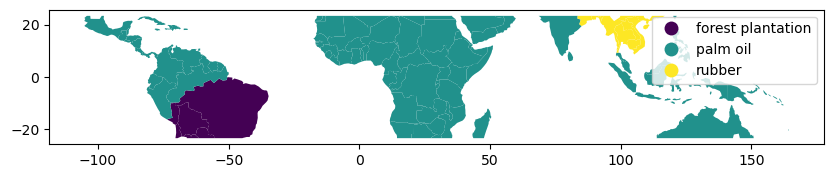

In [8]:
# Example usage
# Load your GeoDataFrame with points and categories (gdf)
# Load a GeoDataFrame for land geometries (land_gdf), e.g., from Natural Earth
land_gdf = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))

# Define bounding box (minx, miny, maxx, maxy)
bounding_box = gdf.total_bounds

# Generate Voronoi polygons restricted to land
land_voronoi_gdf = create_voronoi_on_land(gdf, land_gdf, bounding_box)

# Plot the final result
fig, ax = plt.subplots(figsize=(10, 10))
land_voronoi_gdf.plot(column='category', ax=ax, legend=True, cmap='viridis')
plt.show()

In [9]:

# Get the 'tab20' colormap
cmap = plt.get_cmap('tab20')


import matplotlib.colors as colors

hex_colors = [colors.to_hex(cmap(i)) for i in [4,10,16]]



In [10]:
#palm oil sampleid 80103253  
#urban sampleid 100005898

zz = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels.csv')
zz.loc[zz.sampleid == 80103253].geometry
#zz.loc[zz.sampleid == 100005898].geometry

22964    POINT (111.1250051460671 0.1394634474310269)
Name: geometry, dtype: object

In [11]:
print('adf')

adf


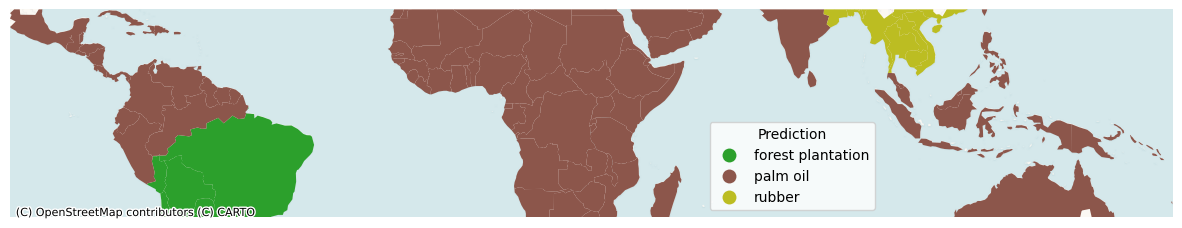

In [29]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf

import contextily as ctx 



# Plot the grid on a basemap
fig, ax = plt.subplots(figsize=(15, 8))

land_voronoi_gdf = land_voronoi_gdf.to_crs(3857)


land_voronoi_gdf.plot(
    column='category',
    #color=aggregated_grid['color'],
    #cmap='viridis',  # Use a qualitative colormap
    cmap=colors.ListedColormap(hex_colors),
    #color=modified_colors,
    legend=True,
    ax=ax,
    legend_kwds={
        #'loc': 'upper center', 
        'bbox_to_anchor': (0.75, 0.49),  # Position below the plot
        'title': 'Prediction',
        #'ncol': 6,  # Number of columns in the legend
        #'fontsize':15,
        #'title_fontsize':15, 
        #'markerscale':1.3,
        # 'labelspacing':0.5,
        # 'handletextpad':0.5,
        #'columnspacing': 0.7
    },
    #edgecolor='k',
    linewidth=0,
)

#Use bbox from the other plot to be consistent
# Calculate the bounding box of the data
minx, miny, maxx, maxy = land_voronoi_gdf.total_bounds



# Set axis limits to the extent of the data (adjust margins if necessary)
ax.set_xlim(minx  , maxx )  # Add small buffer to the bounding box if needed
ax.set_ylim(miny , maxy )

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.VoyagerNoLabels, crs=land_voronoi_gdf.crs, zoom=4)

# Title and labels
#ax.set_title("Training dataset distribution", fontsize=12)
#ax.set_xlabel("Longitude", fontsize=12)
#ax.set_ylabel("Latitude", fontsize=12)
# Remove the axes ticks and labels
ax.set_xticks([])  # Remove longitude ticks
ax.set_yticks([])  # Remove latitude ticks
ax.set_xticklabels([])  # Remove longitude labels
ax.set_yticklabels([])  # Remove latitude labels

# Remove the plot borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)



# Save the figure
#plt.savefig("../paper/location_palm_oil.png", dpi=300, bbox_inches='tight', transparent=True)

plt.show()

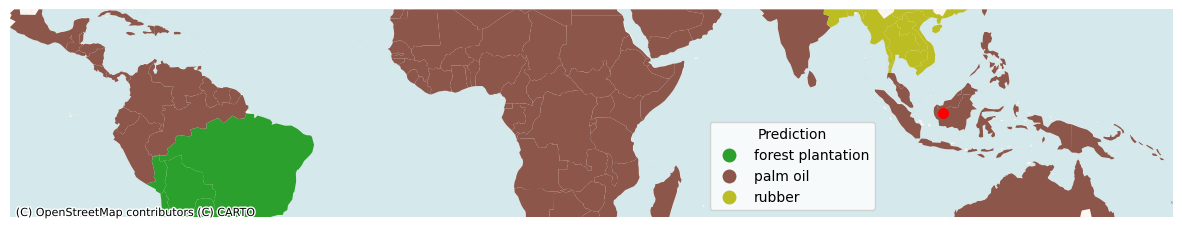

In [37]:
import geopandas as gpd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf
import contextily as ctx
from shapely.geometry import Point

# Define the point location
point_geom = Point(111.1250051460671, 0.1394634474310269)
point_gdf = gpd.GeoDataFrame(geometry=[point_geom], crs="EPSG:4326")
point_gdf = point_gdf.to_crs(3857)

# Plot the grid on a basemap
fig, ax = plt.subplots(figsize=(15, 8))

land_voronoi_gdf = land_voronoi_gdf.to_crs(3857)

land_voronoi_gdf.plot(
    column='category',
    cmap=colors.ListedColormap(hex_colors),
    legend=True,
    ax=ax,
    legend_kwds={
        'bbox_to_anchor': (0.75, 0.49),
        'title': 'Prediction',
    },
    linewidth=0,
)

# Plot the point
point_gdf.plot(ax=ax, color='red', marker='o', markersize=50, label="Point Location")

# Set axis limits to the extent of the data (adjust margins if necessary)
minx, miny, maxx, maxy = land_voronoi_gdf.total_bounds
ax.set_xlim(minx, maxx)
ax.set_ylim(miny, maxy)

# Add basemap
ctx.add_basemap(ax, source=ctx.providers.CartoDB.VoyagerNoLabels, crs=land_voronoi_gdf.crs, zoom=6)

# Title and labels
ax.set_xticks([])
ax.set_yticks([])
ax.set_xticklabels([])
ax.set_yticklabels([])

# Remove the plot borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

# Save the figure
plt.savefig("../paper/location_palm_oil.png", dpi=200, bbox_inches='tight', transparent=True)

plt.show()
